# 02. Phân tích đặc trưng và tensor

## 1. Khởi tạo thư viện và đọc dữ liệu

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'configs/data_config.yaml').is_file())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.data.dataset_loader import DatasetLoader
from src.data.vessel_dataset import VesselDataset
from src.data.encounter_dataset import EncounterDataset
from src.data.tensor_verification import verify, FEATURES
loader = DatasetLoader()
splits = {name: loader.load_split(name) for name in ('train', 'validation')}
plt.rcParams['figure.dpi'] = 100


## 2. Thống kê và phân bố các đặc trưng

,split,feature,min,max,mean,std,median,p01,p99,nan,inf
0,train,own_relative_east_nm,-3.20890,3.32659,0.01289,0.88154,0.00000,-2.09635,2.11682,0,0
1,train,own_relative_north_nm,-3.03195,3.38433,0.00431,0.87868,0.00000,-2.06936,2.11678,0,0
2,train,east_velocity_kn,-22.41997,21.57963,-0.17603,9.94884,-0.10300,-17.04923,18.03223,0,0
3,train,north_velocity_kn,-22.73791,21.32114,-0.05078,9.92574,-0.09401,-17.52380,17.15709,0,0
4,validation,own_relative_east_nm,-2.98522,3.25729,-0.02660,0.64943,0.00000,-1.90091,1.75608,0,0
5,validation,own_relative_north_nm,-3.21958,2.96520,0.01360,0.63948,0.00000,-1.83466,1.74188,0,0
6,validation,east_velocity_kn,-22.42898,22.01008,0.38406,7.35560,0.05576,-15.67954,16.68619,0,0
7,validation,north_velocity_kn,-26.63815,23.86110,-0.15612,7.24415,-0.31236,-15.32899,15.69570,0,0


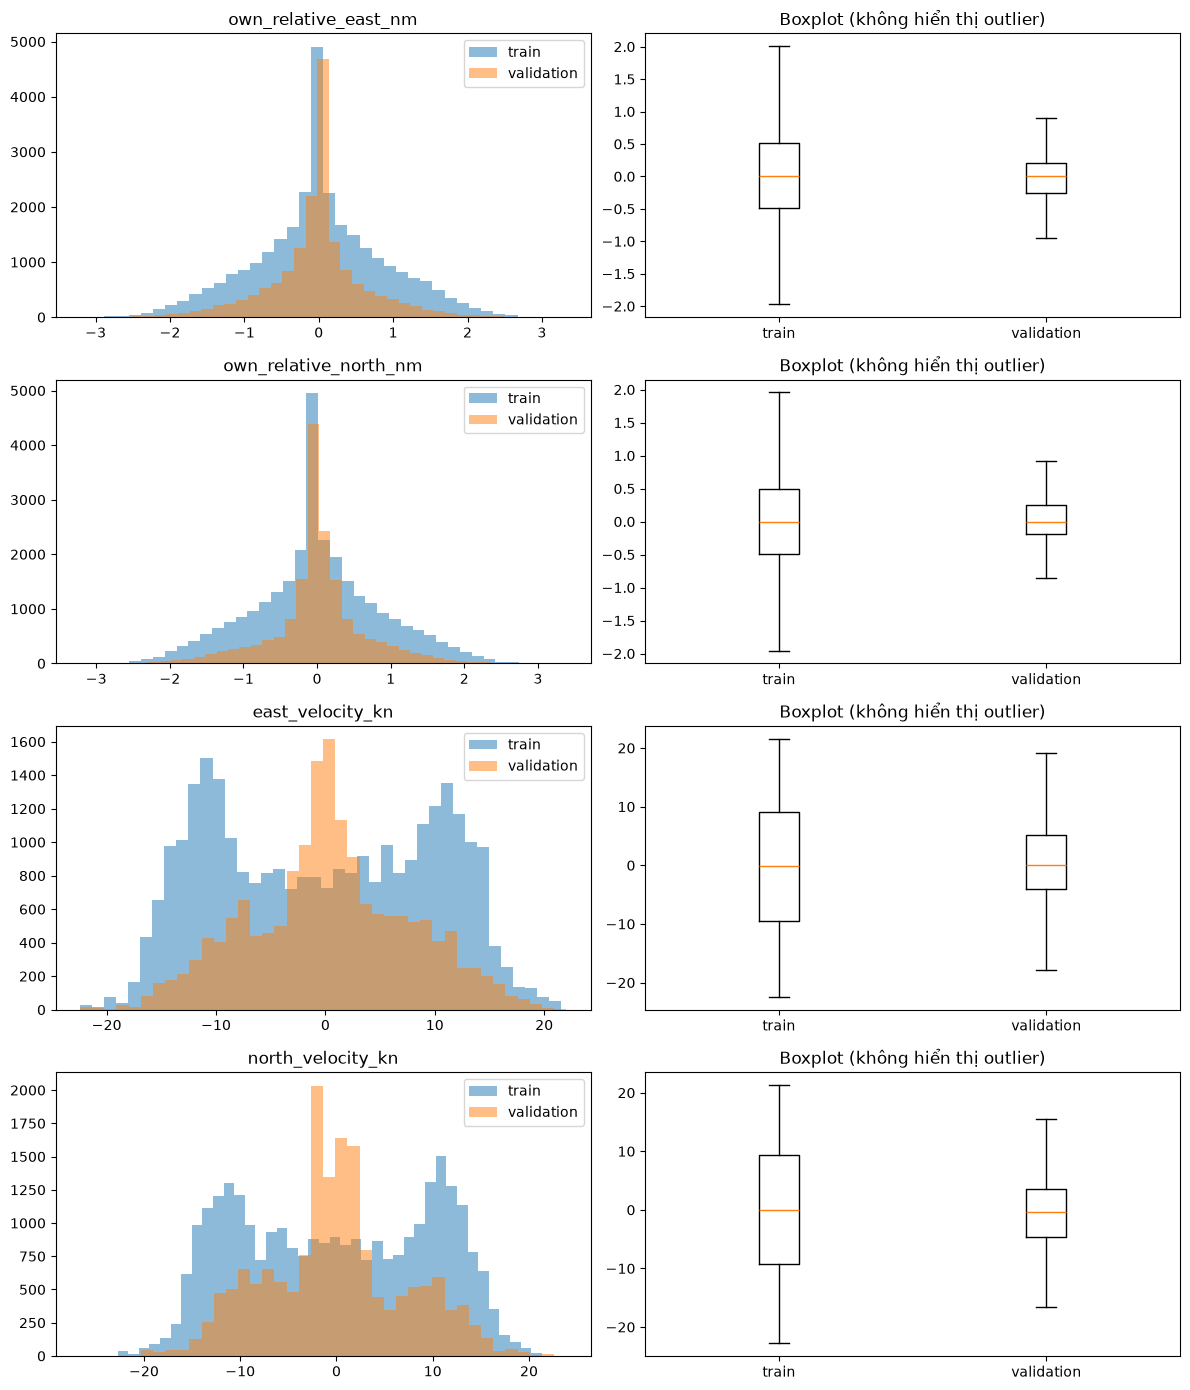

In [2]:
stats=[]
for name,s in splits.items():
    for j,feature in enumerate(FEATURES):
        a=np.asarray(s.X[:,:,j]).ravel(); finite=a[np.isfinite(a)]
        stats.append(dict(split=name,feature=feature,min=float(finite.min()),max=float(finite.max()),mean=float(finite.mean()),std=float(finite.std()),median=float(np.median(finite)),p01=float(np.percentile(finite,1)),p99=float(np.percentile(finite,99)),nan=int(np.isnan(a).sum()),inf=int(np.isinf(a).sum())))
display(pd.DataFrame(stats).round(5))
fig,ax=plt.subplots(4,2,figsize=(12,14))
for j,feature in enumerate(FEATURES):
    samples=[np.asarray(s.X[:,:,j]).ravel() for s in splits.values()]
    for name,a in zip(splits,samples): ax[j,0].hist(a,bins=40,alpha=.5,label=name)
    ax[j,0].set_title(feature); ax[j,0].legend(); ax[j,1].boxplot(samples,tick_labels=list(splits),showfliers=False); ax[j,1].set_title('Boxplot (không hiển thị outlier)')
plt.tight_layout(); plt.show()

## 3. Hệ tọa độ và kiểm tra khả năng khôi phục

In [3]:
s=splits['train']; i=0; rows=s.pairs[i]; side=0; anchor=s.anchors[i,side]; disp=s.displacement[rows[side],0]; common=s.common[i,side,0]; reconstructed=disp.astype('float64')+anchor
display(pd.DataFrame({'anchor':anchor,'displacement_t+1':disp,'common_t+1':common,'reconstructed':reconstructed,'error':reconstructed-common},index=['East','North']))
contract=verify()
display(pd.DataFrame({k:v for k,v in contract['splits'].items() if k != 'test'}).T[['finite','anchor','max_reconstruction_error_nm','timestamp','mutation']])
print('Dung sai nm:',contract['reconstruction_tolerance_nm'], '| Test:',contract['test_scope'])

,anchor,displacement_t+1,common_t+1,reconstructed,error
East,1.102847,0.093496,1.196343,1.196343,1.944715e-10
North,1.260499,0.150248,1.410747,1.410747,4.312710e-09


,finite,anchor,max_reconstruction_error_nm,timestamp,mutation
train,PASS,PASS,0.0,"{'status': 'PASS', 'rows': 72000, 'vessel_grou...","{'future': True, 'label': True, 'metadata': True}"
validation,PASS,PASS,0.0,"{'status': 'PASS', 'rows': 41750, 'vessel_grou...","{'future': True, 'label': True, 'metadata': True}"


Dung sai nm: 1e-06 | Test: integrity, shape, dtype and index metadata only


## 4. Chuẩn bị dữ liệu với PyTorch DataLoader

In [4]:
from torch.utils.data import DataLoader
s=splits['train']; vd=VesselDataset(s); ed=EncounterDataset(s); one=vd[0]
print('X mẫu:',one['X'].numpy().round(3)); print('Y mẫu 2 bước đầu:',one['Y'][:2].numpy().round(3))
dl=DataLoader(vd,batch_size=256,shuffle=False,drop_last=False,num_workers=0)
sizes=[]
for b in dl: sizes.append(len(b['X']))
print('Batch X/Y:', tuple(next(iter(dl))['X'].shape),tuple(next(iter(dl))['Y'].shape),'số batch:',len(sizes),'cuối:',sizes[-1],'tổng:',sum(sizes))
print('Encounter keys:',list(ed[0]),'model_input keys:',list(ed[0]['model_input']))

X mẫu: [[-1.103 -1.26   7.517  8.255]
 [-0.967 -1.118  7.626  8.292]
 [-0.832 -0.977  7.497  8.233]
 [-0.725 -0.841  7.767  8.111]
 [-0.589 -0.707  7.493  8.322]
 [-0.47  -0.566  7.237  8.455]
 [-0.341 -0.434  7.341  8.341]
 [-0.211 -0.29   7.522  8.094]
 [-0.112 -0.155  6.685  8.372]
 [ 0.     0.     6.142  8.752]]
Y mẫu 2 bước đầu: [[0.093 0.15 ]
 [0.171 0.3  ]]


Batch X/Y: (256, 10, 4) (256, 15, 2) số batch: 12 cuối: 64 tổng: 2880
Encounter keys: ['encounter_id', 'vessel_ids', 'model_input', 'ground_truth', 'metadata'] model_input keys: ['X', 'anchors_EN_nm']


## 5. Minh họa Constant Velocity và kiểm tra rò rỉ thông tin

In [5]:
velocity=np.array([12.,-6.]); minutes=np.arange(1,16); cv=minutes[:,None]*velocity[None,:]/60
print('CV shape:',cv.shape,'t+1 và t+15 (nm):',cv[[0,-1]])
display(pd.DataFrame({k:v['mutation'] for k,v in contract['splits'].items() if k != 'test'}))

CV shape: (15, 2) t+1 và t+15 (nm): [[ 0.2 -0.1]
 [ 3.  -1.5]]


,train,validation
future,True,True
label,True,True
metadata,True,True


## 6. Lưu ý về kiểm chứng

Kiểm tra chỉ sử dụng Train và Validation để phân tích. Kiểm tra cách ly đầu vào của loader chưa chứng minh toàn bộ quá trình tạo dữ liệu không có rò rỉ thông tin.